# 【無料公開中】LangChainのススメ【初心者お助けbook】【2025年4月最新版】
# 第三部　前編

## 事前準備

仮想環境の構築や、パッケージインストールなど

In [1]:
#1セル目

!pip uninstall -y google-generativeai
!pip install langchain==0.3.20 langchain_core==0.3.49 langchain_google_genai==2.1.1 httpx==0.28.1 requests==2.32.3 langgraph==0.3.8

Found existing installation: google-generativeai 0.8.4
Uninstalling google-generativeai-0.8.4:
  Successfully uninstalled google-generativeai-0.8.4
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.5/43.5 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 420.1/420.1 kB 34.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.8/40.8 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.6/133.6 kB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 49.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.3/47.3 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.6/223.6 kB 18.9 MB/s eta 0:00:00
  Attempting uninstall: langchain_core
    Found existing installation: langchain-core 0.3.40
    Uninstalling langchain-core-0.3.40:
      S

## chapter14 会話履歴を保持する方法

5セル目まで実行してください。

In [1]:
#2セル目

import os

#環境変数とパッケージの準備
from google.colab import userdata
os.environ["GOOGLE_API_KEY"] = userdata.get("GOOGLE_API_KEY")
#os.environ["GOOGLE_API_KEY"] = "xxxxxxxxxxx" #もしくは最悪ベタガキでも動作する

import operator
from typing import TypedDict, Annotated

from langchain_google_genai import ChatGoogleGenerativeAI

from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.messages import HumanMessage, SystemMessage, AnyMessage


from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import START, END, StateGraph



In [2]:
#3セル目

# geminiモデルを定義する
model = ChatGoogleGenerativeAI(
    model="gemini-2.0-flash",
    temperature=0
)

# messageを作成する
message = [
    SystemMessage(content= "あなたは日本語を話す優秀なアシスタントです。回答には必ず日本語で答えてください。また考える過程も出力してください。"),
    MessagesPlaceholder("messages"),
]

# messageからプロンプトを作成
prompt = ChatPromptTemplate.from_messages(message)

#chainとgraphを作成
chain = prompt | model

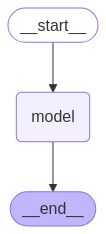

In [3]:
#4セル目

class GraphState(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add]

def create_langgraph(chain):

    def call_llm(state: GraphState):
        response = chain.invoke({"messages":state["messages"]})
        return {"messages": [response]}

    workflow = StateGraph(state_schema=GraphState)
    workflow.add_node("model", call_llm)

    workflow.add_edge(START, "model")
    workflow.add_edge("model", END)

    memory = MemorySaver()
    graph = workflow.compile(checkpointer=memory)
    return graph

graph = create_langgraph(chain)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [4]:
#5セル目

while True:
    query = input("質問を入力してください: ")

    if query.lower() in ["exit", "quit"]:
        print("終了します。")
        break

    print("=================================")
    print("質問:", query)

    input_query = [HumanMessage(
            [
                {
                    "type": "text",
                    "text": f"{query}"
                },
            ]
        )]

    response = graph.invoke({"messages": input_query} ,config={"configurable": {"thread_id": "12345"}})

    print("=================================")
    print("AIの回答",response["messages"][-1].content)




質問を入力してください: 私の名前は山田太郎です。
質問: 私の名前は山田太郎です。
AIの回答 はい、山田太郎さん。承知いたしました。何かお手伝いできることはありますか？
質問を入力してください: 私はサバ料理が好きです
質問: 私はサバ料理が好きです
AIの回答 はい、山田太郎さんはサバ料理がお好きなんですね。承知いたしました。

サバ料理について、何か知りたいことや、私にできることはありますか？例えば、以下のようなことができます。

*   **サバ料理のレシピを提案する:** 和食、洋食、中華など、様々なジャンルのサバ料理のレシピを提案できます。
*   **おすすめのサバ料理店を紹介する:** 山田太郎さんの現在地や好みに合わせて、おすすめのサバ料理店を紹介できます。
*   **サバの栄養や効能について説明する:** サバに含まれる栄養素や、健康に良い効果について説明できます。
*   **サバの旬や選び方について説明する:** 美味しいサバを選ぶためのポイントや、旬の時期について説明できます。

どのような情報にご興味がありますか？
質問を入力してください: exit
終了します。
